In [6]:
pip install scipy numpy pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [10]:
import os
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

=== DADOS CARREGADOS ===
Dimensões do sinal: 394930 amostras x 30 canais
Taxa de amostragem: 200.0 Hz
Duração total: 1974.7 segundos
Canais encontrados: ['Fp1', 'AFF5h', 'AFz', 'F1', 'FC5', 'FC1', 'T7', 'C3', 'Cz', 'CP5', 'CP1', 'P7', 'P3', 'Pz', 'POz', 'O1', 'Fp2', 'AFF6h', 'F2', 'FC2', 'FC6', 'C4', 'T8', 'CP2', 'CP6', 'P4', 'P8', 'O2', 'HEOG', 'VEOG']


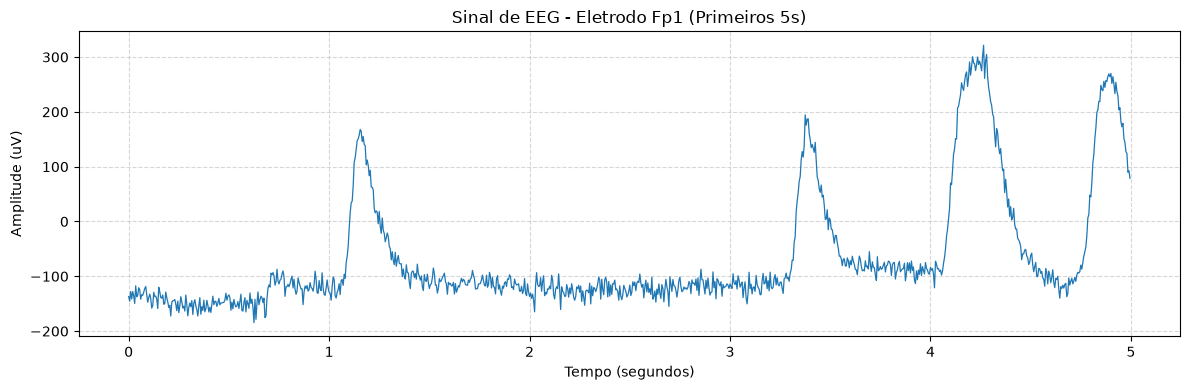

In [11]:
PASTA_PACIENTE = "./VP001-EEG"

caminho_arquivo = os.path.join(PASTA_PACIENTE, "cnt_nback.mat")
mat = sio.loadmat(caminho_arquivo, struct_as_record=False, squeeze_me=True)

chave_cnt = [k for k in mat.keys() if not k.startswith("__")][0]
cnt = mat[chave_cnt]

sinais = cnt.x
fs = float(cnt.fs)
canais = list(cnt.clab)

print("=== DADOS CARREGADOS ===")
print(f"Dimensões do sinal: {sinais.shape[0]} amostras x {sinais.shape[1]} canais")
print(f"Taxa de amostragem: {fs} Hz")
print(f"Duração total: {sinais.shape[0] / fs:.1f} segundos")
print(f"Canais encontrados: {canais}")

canal_teste = canais[0]
idx_canal = canais.index(canal_teste)

segundos = 5
n_amostras = int(segundos * fs)
tempo = np.arange(n_amostras) / fs

plt.figure(figsize=(12, 4))
plt.plot(tempo, sinais[:n_amostras, idx_canal], color="#1f77b4", linewidth=0.9)
plt.title(f"Sinal de EEG - Eletrodo {canal_teste} (Primeiros {segundos}s)")
plt.xlabel("Tempo (segundos)")
plt.ylabel(f"Amplitude ({getattr(cnt, 'yUnit', 'µV')})")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()